<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

HW #4

October 19, 2026

The following is an analysis of a heart disease [dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) with the machine learning repository at UC Irvine. This notebook uses methods and documentatioin from the [breast cancer notebook](https://github.com/bforoura/ML26/blob/main/Module5_SVM_DT/breast_cancer.ipynb). The goal of this assignment is to use support vector machines and decision trees to better understand the likelihood of someone having heart disease based on contributing factors.

This notebook uses code and methods from the class [End-to-End Machine Learning Project](https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb) and makes reference to our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)).

The following installs the library for pulling information from the UC Irvine Repository.

In [1]:
pip install ucimlrepo

# Task 1: Loading the dataset

This method uses the UCI library ("ucimlrepo") to read in the heart disease dataset. We can print out its features and target values.

In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from ucimlrepo import fetch_ucirepo

# # Loading the dataset from UCI: https://archive.ics.uci.edu/dataset/45/heart+disease
heart_disease = fetch_ucirepo(name="Heart Disease")

# data (as pandas dataframes)
X = heart_disease.data.features
#Setting a variable for the original targets
#Replacing values of 2, 3, 4 with 1 in order to create a binary target variable
y = heart_disease.data.targets.replace(2, 1).replace(3, 1).replace(4, 1)

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)

print(X.head)

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

It looks like this dataset is just a partial version, because it does not appear to include the "?" symbols that need to be cleaned. I downloaded each of the processed datasets from the repository. I will concatenate them below. I also replace each of the target values greater than 1 in the dataset with 1. This way, the target value is binary.



In [3]:
#Using the concat function https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.concat.html
#Using the header: https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.read_csv.html
h = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
hungarian = pd.read_csv("processed.hungarian.data", names=h)
cleveland = pd.read_csv("processed.cleveland.data", names=h)
switzerland = pd.read_csv("processed.switzerland.data", names=h)
va = pd.read_csv("processed.va.data", names=h)

data = pd.concat([hungarian, cleveland, switzerland, va])


X_all = data[['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal']]
#Replacing all values of 2, 3, and 4 with 1
y = data['num'].replace(2, 1).replace(3, 1).replace(4, 1)

# Task 2: Inspection Methods

After loading in all four processed datasets from the repository, we can see that a number of values are recorded as objects, because they have "?" characters. The following uses methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation to inspect the dataframe for missing values and imputing values.

In [4]:
print(X_all.head())
X_all.info()

    age  sex   cp trestbps chol fbs restecg thalach exang oldpeak slope ca  \
0  28.0  1.0  2.0      130  132   0       2     185     0     0.0     ?  ?   
1  29.0  1.0  2.0      120  243   0       0     160     0     0.0     ?  ?   
2  29.0  1.0  2.0      140    ?   0       0     170     0     0.0     ?  ?   
3  30.0  0.0  1.0      170  237   0       1     170     0     0.0     ?  ?   
4  31.0  0.0  2.0      100  219   0       1     150     0     0.0     ?  ?   

  thal  
0    ?  
1    ?  
2    ?  
3    6  
4    ?  
<class 'pandas.core.frame.DataFrame'>
Index: 920 entries, 0 to 199
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  920 non-null    object 
 4   chol      920 non-null    object 
 5   fbs       920 non-null    object 
 6   restecg   920 non-null    object 
 7   thalach   920 non-nul

Because object variables may have white space, we may need to remove this white space and replace with `np.nan` to view any variables that require imputation. The following tutorials were helpful for reference:

- [Stack Overflow](https://stackoverflow.com/questions/59476179/is-it-possible-to-change-pandas-column-data-type-within-a-sklearn-pipeline) post describing how to change a datatype in a pipeline.

- [GeeksForGeeks](https://www.geeksforgeeks.org/pandas/pandas-strip-whitespace-from-entire-dataframe/) discussing how to strip white space from columns.

- [Pandas Documentation](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.replace.html) describing methods for replacing values in a dataframe. This is used to replace empty white space values with `np.nan`.

- [Geeks For Geeks](https://www.geeksforgeeks.org/python/how-to-convert-data-types-in-python-3/) describing how to convert data types.

- [Stack Overflow Article](https://stackoverflow.com/questions/43677933/converting-object-to-int-pandas) describing how to convert objects to int data types.

Below we take a copy of the dataframe so that we can inspect missing values after replacing the "?" symbols.

In [5]:
# Replacing ? with np.nan
# With reference to: https://www.geeksforgeeks.org/data-analysis/python-pandas-dataframe-replace/#google_vignette

X_copy = X_all

X_copy['trestbps'] = X_copy['trestbps'].str.strip().replace('?', np.nan).astype(float)
X_copy['chol'] = X_copy['chol'].str.strip().replace('?', np.nan).astype(float)
X_copy['fbs'] = X_copy['fbs'].str.strip().replace('?', np.nan).astype(float)
X_copy['restecg'] = X_copy['restecg'].str.strip().replace('?', np.nan).astype(float)
X_copy['thalach'] = X_copy['thalach'].str.strip().replace('?', np.nan).astype(float)
X_copy['exang'] =  X_copy['exang'].str.strip().replace('?', np.nan).astype(float)
X_copy['oldpeak'] = X_copy['oldpeak'].str.strip().replace('?', np.nan).astype(float)
X_copy['slope'] = X_copy['slope'].str.strip().replace('?', np.nan).astype(float)
X_copy['ca'] = X_copy['ca'].str.strip().replace('?', np.nan).astype(float)
X_copy['thal'] = X_copy['thal'].str.strip().replace('?', np.nan).astype(float)

/tmp/ipykernel_43449/2749332458.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_copy['trestbps'] = X_copy['trestbps'].str.strip().replace('?', np.nan).astype(float)
/tmp/ipykernel_43449/2749332458.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_copy['chol'] = X_copy['chol'].str.strip().replace('?', np.nan).astype(float)
/tmp/ipykernel_43449/2749332458.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value 

Now we can see that all ? values have been replaced with missing values. These can be imputed with a pipeline.

In [6]:
X_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 920 entries, 0 to 199
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  558 non-null    float64
 4   chol      464 non-null    float64
 5   fbs       527 non-null    float64
 6   restecg   415 non-null    float64
 7   thalach   562 non-null    float64
 8   exang     562 non-null    float64
 9   oldpeak   261 non-null    float64
 10  slope     308 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
dtypes: float64(13)
memory usage: 100.6 KB


In [7]:
# Display the first 5 rows
display(X_copy.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(X_copy.info())
display(X_copy.describe())

# Display the first 5 rows
display(y.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(y.info())
display(y.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,28.0,1.0,2.0,130.0,132.0,0.0,2.0,185.0,0.0,NaN,NaN,NaN,NaN
1,29.0,1.0,2.0,120.0,243.0,0.0,0.0,160.0,0.0,NaN,NaN,NaN,NaN
2,29.0,1.0,2.0,140.0,NaN,0.0,0.0,170.0,0.0,NaN,NaN,NaN,NaN
3,30.0,0.0,1.0,170.0,237.0,0.0,1.0,170.0,0.0,NaN,NaN,NaN,6.0
4,31.0,0.0,2.0,100.0,219.0,0.0,1.0,150.0,0.0,NaN,NaN,NaN,NaN



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 920 entries, 0 to 199
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  558 non-null    float64
 4   chol      464 non-null    float64
 5   fbs       527 non-null    float64
 6   restecg   415 non-null    float64
 7   thalach   562 non-null    float64
 8   exang     562 non-null    float64
 9   oldpeak   261 non-null    float64
 10  slope     308 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
dtypes: float64(13)
memory usage: 100.6 KB


None

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,920.000000,920.000000,920.000000,558.000000,464.000000,527.000000,415.000000,562.000000,562.000000,261.000000,308.000000,309.000000,434.000000
mean,53.510870,0.789130,3.250000,132.372760,220.857759,0.176471,0.260241,131.042705,0.423488,1.021839,1.938312,0.676375,5.087558
std,9.424685,0.408148,0.930969,19.828097,96.580125,0.381582,0.505749,25.151341,0.494551,1.131856,0.575923,0.935653,1.919075
min,28.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,3.000000
25%,47.000000,1.000000,3.000000,120.000000,195.000000,0.000000,0.000000,114.250000,0.000000,0.000000,2.000000,0.000000,3.000000
50%,54.000000,1.000000,4.000000,130.000000,227.500000,0.000000,0.000000,130.000000,0.000000,1.000000,2.000000,0.000000,6.000000
75%,60.000000,1.000000,4.000000,142.000000,274.000000,0.000000,0.000000,150.000000,1.000000,2.000000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,190.000000,1.000000,4.000000,3.000000,3.000000,7.000000


,num
0,0
1,0
2,0
3,0
4,0



Dataset Information:
<class 'pandas.core.series.Series'>
Index: 920 entries, 0 to 199
Series name: num
Non-Null Count  Dtype
--------------  -----
920 non-null    int64
dtypes: int64(1)
memory usage: 14.4 KB


None

,num
count,920.000000
mean,0.553261
std,0.497426
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


# Task 3: Assessing Missing Values

We can take a distribution to better understand how to impute missing values. We can see that many continuous features form a standard distribution. We can use a Standard imputer for these columns.


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'cp'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'fbs'}>,
        <Axes: title={'center': 'restecg'}>,
        <Axes: title={'center': 'thalach'}>],
       [<Axes: title={'center': 'exang'}>,
        <Axes: title={'center': 'oldpeak'}>,
        <Axes: title={'center': 'slope'}>,
        <Axes: title={'center': 'ca'}>],
       [<Axes: title={'center': 'thal'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

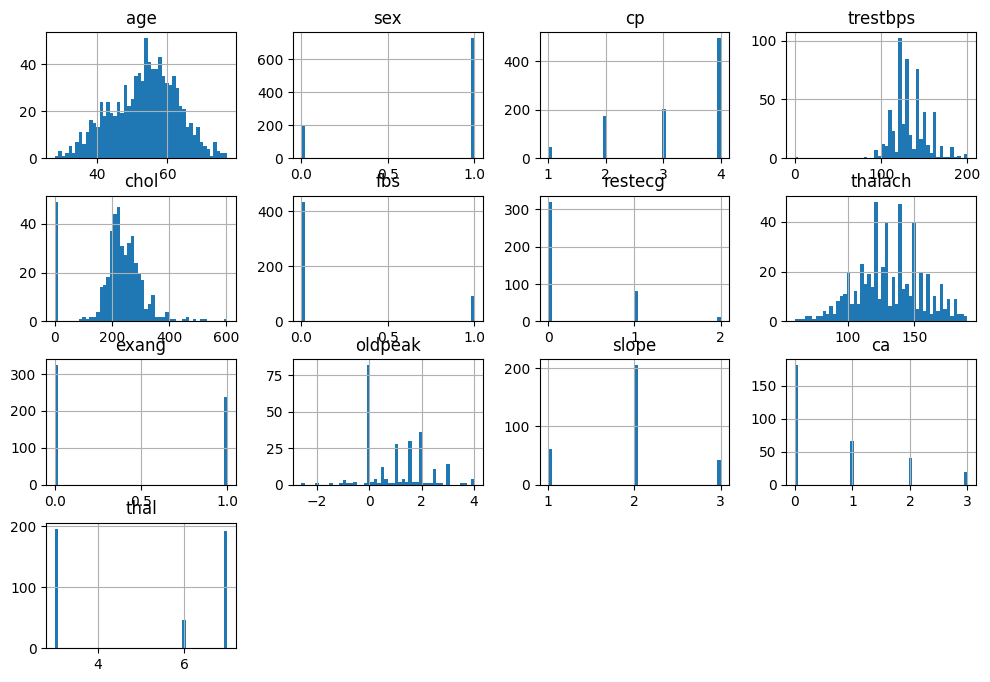

In [8]:
X_copy.hist(bins=50, figsize=(12, 8))

# Task 4: Building Pipelines

Here, we create pipelines for both numeric and categorical features to preprocess data and then define pipeline for Support Vector Classification (SVC), Decision Tree Classification, and a SVC classification that uses a grid search to identify the ideal parameters, c and gamma.

The following uses methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation to create a pipeline for numeric and categorical variables.

In [9]:
#Importing the method for a pipeline
from sklearn.pipeline import Pipeline
#Importing a simple imputer for filling empty values
from sklearn.impute import SimpleImputer
#Importing a one hot encoder for creating dummy variables for categorical data
from sklearn.preprocessing import OneHotEncoder
#Importing libraries for creating pipelines and a transformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
#Importing a Standard Scaler to standardize values.
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import make_column_selector, make_column_transformer

#Importing SGD Classifier
from sklearn.linear_model import SGDClassifier

#Importing SVC
from sklearn.svm import SVC

# Using methods from "end-to-end machine learning project"
from sklearn.preprocessing import FunctionTransformer

# Using https://archive.ics.uci.edu/dataset/45/heart+disease to identify
# numeric and categorical features
numeric_features = [
    'age','trestbps', 'chol', 'thalach', 'oldpeak'
]
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'slope', 'exang', 'ca', 'thal']

# Using a custom function for converting data types with reference to:
#https://pythonskillset.com/code-samples/convert-data-types-python-pipeline/
#https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb
def clean_type(d):
  if type(d) == "str":
    d = d.strip()
    if d == "?":
      d = np.nan
    return d.astype(float)
  else:
    return d

#Importing libraries for Decision Trees, cross validation scoring,
# and creating a classification report
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report


# The following defines the pipeline for numeric values that imputes
# a median value and a standard scaler.
numeric_transformer_standard = Pipeline(steps=[
    ('clean_data', FunctionTransformer(clean_type)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# The following is a transformer that imputes values with their most
# frequent entry and one-hot encodes each of them.
categorical_transformer = Pipeline(steps=[
    ('clean_data', FunctionTransformer(clean_type)),
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Defining a ColumnTransformer for transforming both numeric and
# categorical features.
preprocessor_standard = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_standard, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Creating full pipeline for the svc classifier
svc = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    ('classifier', SVC(C=1.0, kernel='rbf', random_state=42, probability=True))

])

# Creating full pipeline for the decision tree classifier using the
# configuration from the breast cancer notebook.
dtc = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42))
])

# GridSearch pipeline
from sklearn.model_selection import GridSearchCV

#With reference to parameters from pg. 153 of the Texbook,
# the following uses various parameters for C and gamma for the grid search.
params = {
    'C': [0.001, 0.01, 0.1, 0, 1, 10, 100, 1000],
    'gamma': [0.1, 0, 1, 2, 3, 4, 5]
}
# Using documentation from: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
# creating a pipeline that uses grid search to find ideal parameters for C and gamma.
grid = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # With reference to pages 152-153 of the textbook,
    # implementing the svc with grid search
    ('classifier', GridSearchCV(
        SVC(kernel='rbf', random_state=42, probability=True), param_grid=params))
])

print("Pipelines constructed successfully.")

Pipelines constructed successfully.


# Results

The following defines a function that displays a confusion matrix, classification report and ROC-AUC curve for Tasks 5 and 6. This function uses code and methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation.

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
import pandas as pd
from sklearn.model_selection import train_test_split

def results(test_size_var, pipeline):
  # Split data into training and testing sets
  X = X_all
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size_var, random_state=42)

  # Fit the model on the full training data
  pipeline.fit(X_train, y_train)

  # Generate predictions for training and testing sets
  y_pred = pipeline.predict(X_test)
  y_scores = pipeline.predict_proba(X_test)[:,1]

  #Using the Pipeline documentation for get_params:https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

  # Print classification report
  print("Classification Report:")
  print(classification_report(y_test, y_pred))

  # Plot Confusion Matrix
  fig, ax = plt.subplots(figsize=(6, 6))
  ConfusionMatrixDisplay.from_estimator(pipeline, X_test, y_test, ax=ax, cmap='Blues', values_format='d')
  plt.title('Confusion Matrix')
  plt.show()

  # Compute ROC Curve and ROC-AUC
  fpr, tpr, thresholds = roc_curve(y_test, y_scores)
  roc_auc = auc(fpr, tpr)

  # Plot ROC Curve
  plt.figure(figsize=(6, 6))
  plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
  plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
  plt.xlim([0.0, 1.0])
  plt.ylim([0.0, 1.05])
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('Receiver Operating Characteristic (ROC) Curve')
  plt.legend(loc="lower right")
  plt.show()

  # Extract feature names from the preprocessor step
  cat_encoder = pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
  encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

  # Combine numerical and encoded categorical feature names
  all_feature_names = numeric_features + encoded_cat_features

# Task 5: SVC

Using a support vector classifier, we can see that it creates a classification model with an AUC = 0.82.

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.73      0.70        73
           1       0.81      0.77      0.79       111

    accuracy                           0.75       184
   macro avg       0.74      0.75      0.74       184
weighted avg       0.75      0.75      0.75       184



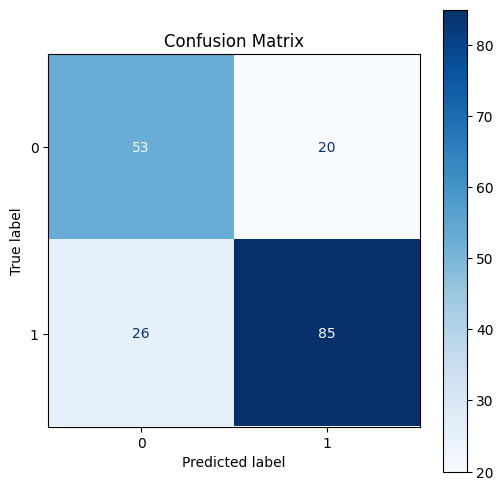

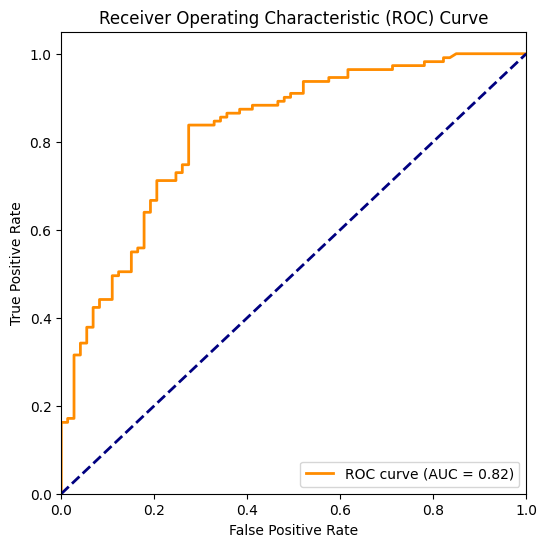

In [11]:
results(0.2, svc)

# Task 6: Decision Tree

The following uses a decision tree classification. We see that it performs less effectively than the SVC classifier with an AUC score of 0.80.

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.77      0.67        73
           1       0.81      0.67      0.73       111

    accuracy                           0.71       184
   macro avg       0.71      0.72      0.70       184
weighted avg       0.73      0.71      0.71       184



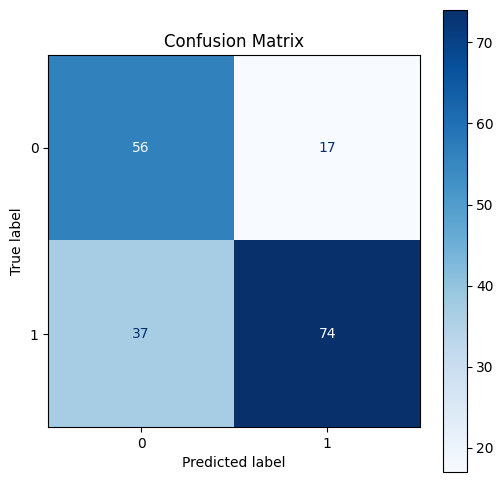

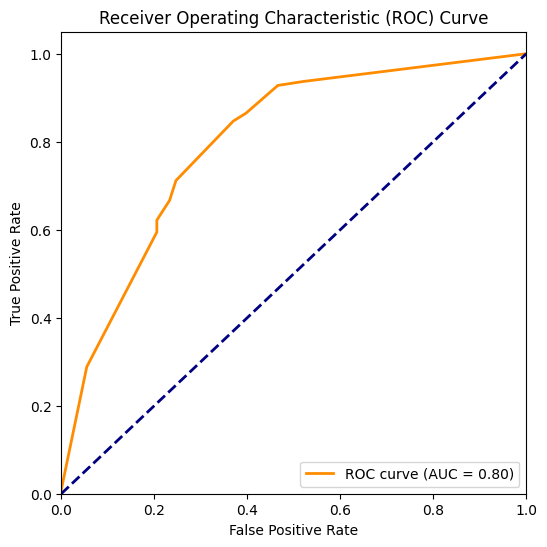

In [12]:
results(0.2, dtc)

# Task 7: GridSearchCV

The following reports results of a GridSearch that uses ideal parameters for the support vector classifier. We can see that this results in a model with an AUC score of 0.82, the same as the SVC classifier above.  

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
35 fits failed out of a total of 280.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
35 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_pa

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.73      0.70        73
           1       0.81      0.77      0.79       111

    accuracy                           0.75       184
   macro avg       0.74      0.75      0.74       184
weighted avg       0.75      0.75      0.75       184



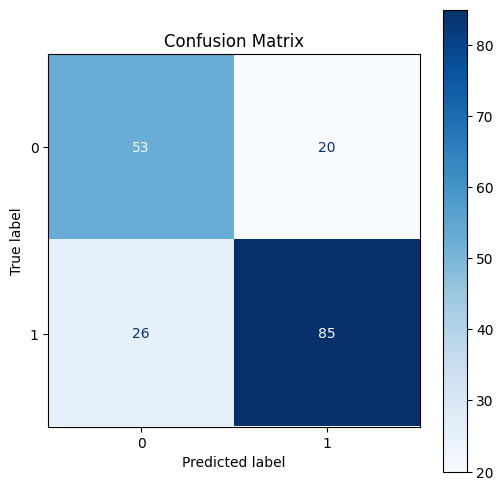

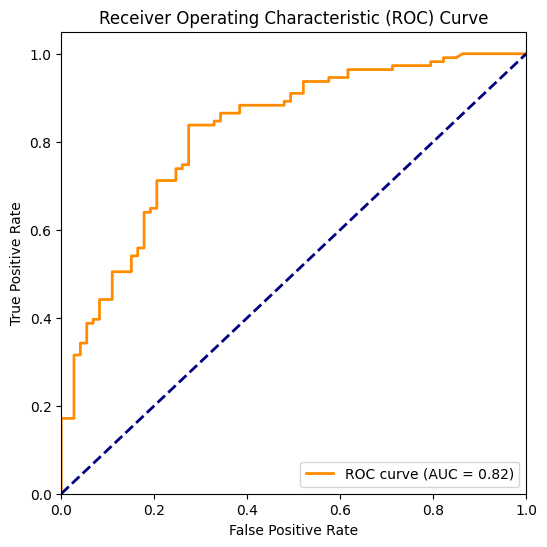

In [13]:
results(0.2, grid)

Here we can print out the configurations for the best estimator. The GridSearch used a C of 1 and a gamma of 0.1.

In [14]:
print(grid.named_steps['classifier'].best_estimator_)

SVC(C=1, gamma=0.1, probability=True, random_state=42)


# **Task 8: Decision Tree Diagram**


The following uses a plot to visualize the decision tree fitted in the previous model and uses methods and documentation from the [breast cancer notebook](https://github.com/bforoura/ML26/blob/main/Module5_SVM_DT/breast_cancer.ipynb). One can see that the first division is drawn at chest pain. If a patient experiences chest pain, the decision tree designates them as having a higher chance of heart disease. The tree then divides subsets of data across age, sex, the presence of defects, and exercise-induced angina.




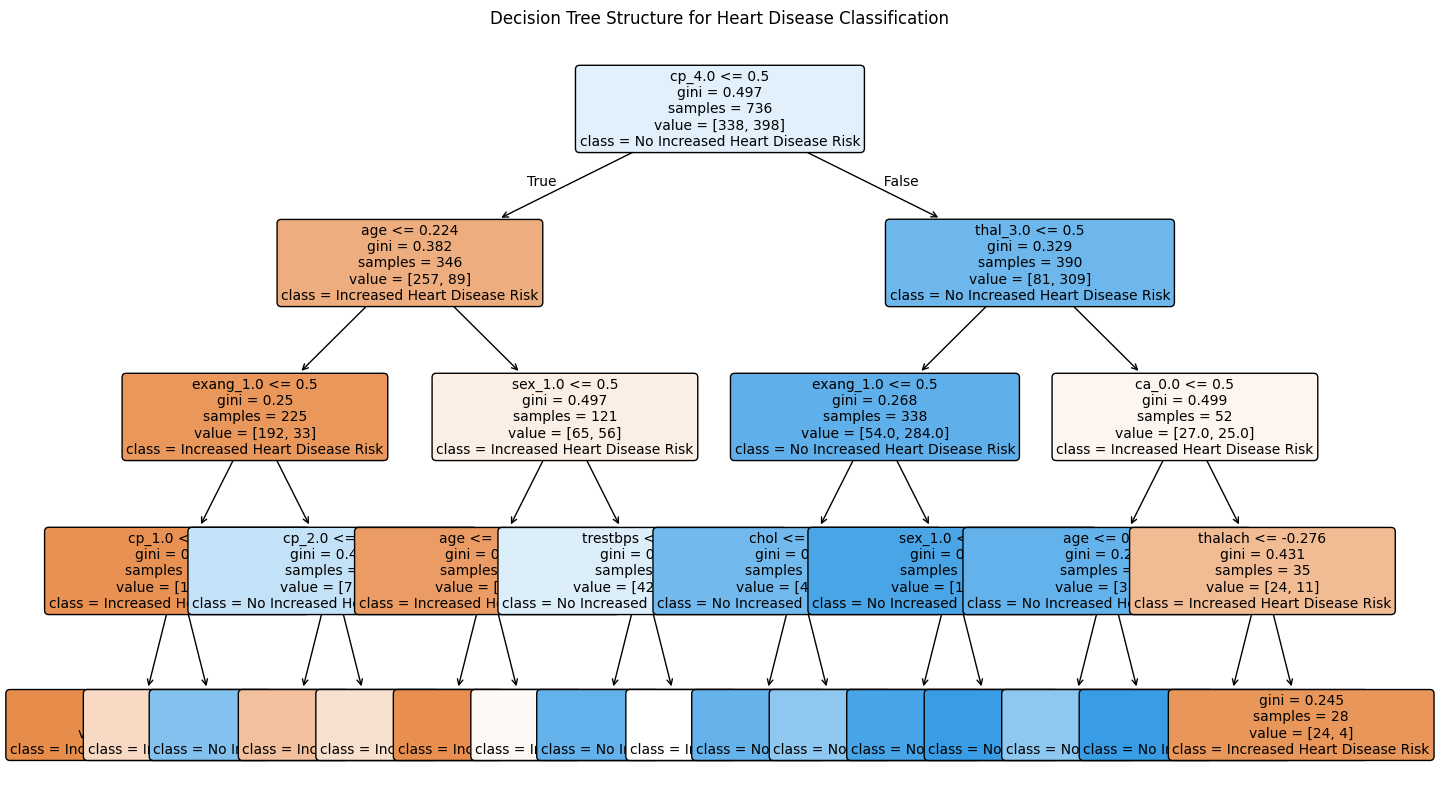

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

numeric_features = [
    'age','trestbps', 'chol', 'thalach', 'oldpeak'
]

# Extract feature names from the preprocessor step
cat_encoder = dtc.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

# Combine numerical and encoded categorical feature names
all_feature_names = numeric_features + encoded_cat_features

# Plot the trained decision tree
plt.figure(figsize=(16, 10))
plot_tree(
    dtc.named_steps["classifier"],
    #Troubleshooting feature names
    #https://stackoverflow.com/questions/66552426/how-to-display-feature-names-in-sklearn-decision-tree
    feature_names=all_feature_names,
    class_names=["Increased Heart Disease Risk", "No Increased Heart Disease Risk"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure for Heart Disease Classification")
plt.show()